# Two-step blend (P01b): cross-fitted image score plus measurements

**Question.** Do the three predicted cup-to-disc ratios improve an image score that was never fitted on its own images?

The design and the decision rule were written before any model was trained (`docs/experiment_log.md`, "P01b design"). This notebook reads only the saved result tables in `docs/p01b_evidence/` and the freeze record, so it needs no patient data.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from glaucoma_project import REPO_ROOT

EVIDENCE = REPO_ROOT / "docs" / "p01b_evidence"
PARTITION_NAMES = {"in_domain_test": "CHAKSU test", "external_test": "PAPILA (external)"}
pd.set_option("display.precision", 3)


def name_partitions(table):
    return table.assign(partition=table.partition.map(PARTITION_NAMES))


def verdict(ci_low):
    return "improvement" if ci_low > 0 else "not shown"


def plot_differences(table, title):
    fig, ax = plt.subplots(figsize=(6, 2.2))
    for y, row in enumerate(table.itertuples()):
        ax.errorbar(row.difference, y, xerr=[[row.difference - row.ci_low], [row.ci_high - row.difference]], fmt="o", capsize=4)
    ax.axvline(0, color="grey", linestyle="--")
    ax.set_yticks(range(len(table)), table.partition)
    ax.set_xlabel(title)
    plt.show()

## 1. The frozen record
Before any test image was opened, the code version and the SHA-256 hash of the 25 checkpoints, the fitted blend, the measurements file and the split file were recorded.

In [2]:
record = json.loads((REPO_ROOT / "docs" / "frozen_p01b.json").read_text())
print("frozen at commit", record["git_commit"][:7], "| code paths guarded:", len(record["code_paths"]))
print("files recorded:", len(record["files"]))
print("study settings:", record["settings"]["study"])

frozen at commit 31fd3c8 | code paths guarded: 12
files recorded: 28
study settings: {'recipe': {'model_name': 'resnet18', 'pretrained': True, 'batch_size': 16, 'warmup_epochs': 2, 'head_lr': 0.0001, 'backbone_lr': 1e-05, 'weight_decay': 0.0001, 'augment': True}, 'epochs': 10, 'n_folds': 5, 'fold_seed': 2440, 'seeds': [2440, 2441, 2442, 2443, 2444], 'c_grid': [0.001, 0.01, 0.1, 1, 10, 100], 'runs_dir': 'runs/p01b', 'measurements': 'runs/p01/measurements.csv', 'baseline_a_scores': 'runs/final/common_split/scores.csv', 'n_bootstrap': 2000, 'bootstrap_seed': 2440}


## 2. Development diagnostic (before freezing, not a decision rule)
Out-of-fold AUC of the image score, and cross-validated AUC of the blend, on the 1,008 development images.

In [3]:
development = json.loads((EVIDENCE / "development.json").read_text())
display(pd.Series(development, name="value").to_frame())

,value
c,1.000
n_development_images,1008.000
image_only_auc,0.854
blend_cv_auc,0.957


## 3. Primary comparison
Blend minus image score alone, AUC, paired bootstrap over whole patient groups (2,000 resamples), each test set on its own. **Decision rule:** an improvement is claimed only if the 95% interval excludes 0.

,partition,n_images,n_positives,blend AUC,image-score AUC,difference,ci_low,ci_high,verdict
0,CHAKSU test,335,51,0.945,0.837,0.108,0.040,0.175,improvement
1,PAPILA (external),420,87,0.749,0.779,-0.030,-0.101,0.040,not shown


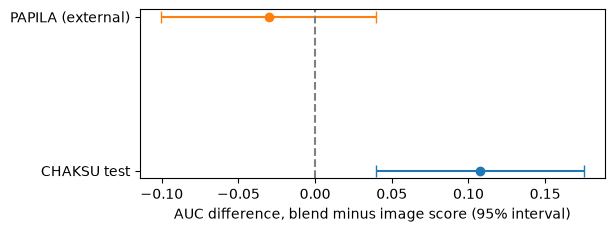

In [4]:
primary = name_partitions(pd.read_csv(EVIDENCE / "primary.csv"))
primary["verdict"] = primary.ci_low.map(verdict)
display(primary[["partition", "n_images", "n_positives", "auc_a", "auc_b", "difference", "ci_low", "ci_high", "verdict"]]
        .rename(columns={"auc_a": "blend AUC", "auc_b": "image-score AUC"}))
plot_differences(primary, "AUC difference, blend minus image score (95% interval)")

## 4. Secondary comparison: blend against the measurements alone
On the images the blend and Baseline A share. This shows what the image score adds on top of the three ratios.

,partition,n_images,blend AUC,measurements-only AUC,difference,ci_low,ci_high,verdict
0,CHAKSU test,326,0.945,0.943,0.001,-0.004,0.007,not shown
1,PAPILA (external),418,0.745,0.731,0.014,0.004,0.024,improvement


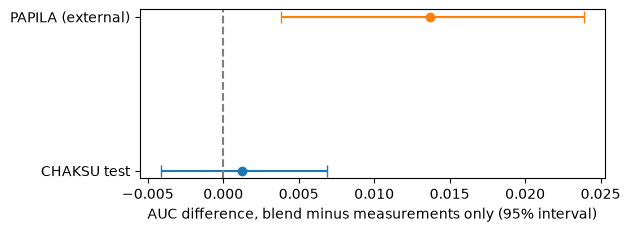

In [5]:
secondary = name_partitions(pd.read_csv(EVIDENCE / "secondary.csv"))
secondary["verdict"] = secondary.ci_low.map(verdict)
display(secondary[["partition", "n_images", "auc_a", "auc_b", "difference", "ci_low", "ci_high", "verdict"]]
        .rename(columns={"auc_a": "blend AUC", "auc_b": "measurements-only AUC"}))
plot_differences(secondary, "AUC difference, blend minus measurements only (95% interval)")

## Reading the result

- **CHAKSU test: improvement over the image score** (+0.108, interval above 0). The blend (0.945) is no better than the three ratios alone (0.943), so the gain is the ratios, not a joint effect. CHAKSU labels follow cup size, so this is the expected result.
- **PAPILA: improvement not shown** (-0.030, interval includes 0). The blend is not better than the image score on a new camera and hospital.
- On PAPILA the blend is slightly ahead of the ratios alone (+0.014, interval 0.004 to 0.024). The size of the gain is small and the PAPILA test set was used by earlier experiments, so this is exploratory.
- The pre-registered question, about an image score that did not memorise its labels, is answered: the ratios help on CHAKSU only because they carry CHAKSU's label definition.